# Merge and Visualise Data

In [1]:
import numpy as np
import joblib
from collections import Counter


def visualise_data(filename):
    # Load the dataset
    data = np.load(filename, allow_pickle=True)

    # Check total samples
    print(f"Total samples collected: {len(data)}")

    # Extract actions from (state, action) pairs
    states, actions = zip(*data)
    states = np.array(states)
    actions = np.array(actions)

    # Count occurrences of each action
    action_counts = Counter(actions)
    print(f"Action distribution: {action_counts}")


def merge_datasets(
    filenames, total_samples, go_ratio, filename="training_data.npy"
):
    # Load the datasets
    datasets = [np.load(f, allow_pickle=True) for f in filenames]

    # Merge the datasets
    merged_dataset = np.concatenate(datasets)

    modified_dataset = []
    for state, action in merged_dataset:
        self_distance_to_goal = state[2]  # Self-plane distance to end goal

        # Convert distances to priority (1 = higher priority, 0 = lower priority)
        state[6] = (
            1 if state[6] < self_distance_to_goal else 0
        )  # Nearest Plane 1 Priority
        state[10] = (
            1 if state[10] < self_distance_to_goal else 0
        )  # Nearest Plane 2 Priority

        # Encode overall priority decision (self-plane has priority or not)
        state[2] = 1 if state[6] == 0 and state[10] == 0 else 0

        plane1_distance = state[4]
        plane1_relative_angle = state[5]
        plane1_relative_angle = np.cos(np.radians(plane1_relative_angle))
        plane1_projected_distance = plane1_distance * plane1_relative_angle
        state[4] = plane1_projected_distance

        plane2_distance = state[8]
        plane2_relative_angle = state[9]
        plane2_relative_angle = np.cos(np.radians(plane2_relative_angle))
        plane2_projected_distance = plane2_distance * plane2_relative_angle
        state[8] = plane2_projected_distance

        modified_dataset.append((state, action))

    # Separate Go (0) and Stop (1) actions
    go_cases = [pair for pair in modified_dataset if pair[1] == 0]
    stop_cases = [pair for pair in modified_dataset if pair[1] == 1]

    # Ensure we get the correct ratio in an 80,000-sample dataset
    num_go = int(total_samples * go_ratio)  # 75% Go
    num_stop = total_samples - num_go  # 25% Stop

    # Sample the required amount of Go and Stop cases
    go_cases = np.array(go_cases, dtype=object)
    stop_cases = np.array(stop_cases, dtype=object)

    go_indices = np.random.choice(
        len(go_cases), size=min(num_go, len(go_cases)), replace=False
    )
    stop_indices = np.random.choice(
        len(stop_cases), size=min(num_stop, len(stop_cases)), replace=False
    )

    sampled_go = go_cases[go_indices]
    sampled_stop = stop_cases[stop_indices]

    # Merge balanced dataset
    balanced_dataset = np.concatenate([sampled_go, sampled_stop])

    # Shuffle dataset
    np.random.shuffle(balanced_dataset)

    # Remove the first two features (reducing dimensionality)
    balanced_dataset = [(state[3:], action) for state, action in balanced_dataset]

    # Save the merged dataset
    np.save(filename, np.array(balanced_dataset, dtype=object))
    print(
        f"✅ Saved merged dataset to {filename} with {len(balanced_dataset)} samples ({go_ratio:.0%} Go / {1 - go_ratio:.0%} Stop)."
    )


# Merge datasets with a **total size of 80,000 samples and a 75-25 split**
merge_datasets(
    ["raw_training_data_1.npy", "raw_training_data_2.npy"],
    total_samples=100_000,
    go_ratio=0.50,
)
visualise_data("training_data.npy")

✅ Saved merged dataset to training_data.npy with 100000 samples (50% Go / 50% Stop).
Total samples collected: 100000
Action distribution: Counter({1: 50000, 0: 50000})


# Standardisation

In [2]:
from sklearn.preprocessing import StandardScaler

# Extract states (features) and actions
data = np.load("training_data.npy", allow_pickle=True)
states, actions = zip(*data)
states = np.array(states)

# Apply Standardisation
scaler = StandardScaler()
scaled_states = scaler.fit_transform(states)

# Save standardized dataset
standardized_data = list(zip(scaled_states, actions))
np.save("standardised_data/standardised_training_data.npy", np.array(standardized_data, dtype=object))
print("Standardised data successfully saved!")

# Save the scaler for inference
joblib.dump(scaler, "standardised_data/standard_scaler.pkl")
print("Standard Scaler saved!")

Standardised data successfully saved!
Standard Scaler saved!


# Min-Max Normalisation

In [3]:
from sklearn.preprocessing import MinMaxScaler

# Extract states (features) and actions
data = np.load("training_data.npy", allow_pickle=True)
states, actions = zip(*data)
states = np.array(states)

# Apply Min-Max Scaling
scaler = MinMaxScaler()
scaled_states = scaler.fit_transform(states)

# Save normalized dataset
normalized_data = list(zip(scaled_states, actions))
np.save("minmax_data/minmax_training_data.npy", np.array(normalized_data, dtype=object))
print("Min-Max normalised data successfully saved!")

# Save the scaler for inference
joblib.dump(scaler, "minmax_data/minmax_scaler.pkl")
print("Min-Max Scaler saved!")

Min-Max normalised data successfully saved!
Min-Max Scaler saved!


# Logisitic Regression

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

def logistic_regression(data_path):
    # Load dataset
    data = np.load(data_path, allow_pickle=True)
    states, actions = zip(*data)
    states = np.array(states)
    actions = np.array(actions)

    # Split dataset
    X_train, X_test, y_train, y_test = train_test_split(
		states, actions, test_size=0.2, random_state=42
	)

    # Train Logistic Regression
    model = LogisticRegression()
    model.fit(X_train, y_train)

    # Evaluate
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)
    print(f"Logistic Regression Accuracy for {data_path}: {accuracy * 100:.2f}%")
    print(cm)

    joblib.dump(model, "linear_regression_model.pkl")

# Test on standardised data
logistic_regression("standardised_data/standardised_training_data.npy")

# Test on min-max normalised data
# logistic_regression("minmax_data/minmax_training_data.npy")

Logistic Regression Accuracy for standardised_data/standardised_training_data.npy: 69.42%
[[7330 2641]
 [3475 6554]]


# Decision Tree

In [5]:
from sklearn.tree import DecisionTreeClassifier

def decision_tree(data_path):
	# Load dataset
	data = np.load(data_path, allow_pickle=True)
	states, actions = zip(*data)
	states = np.array(states)
	actions = np.array(actions)

	# Split dataset
	X_train, X_test, y_train, y_test = train_test_split(
		states, actions, test_size=0.2, random_state=42
	)

	# Train Decision Tree
	tree = DecisionTreeClassifier(max_depth=5)  # Limit depth to prevent overfitting
	tree.fit(X_train, y_train)

	# Evaluate
	y_pred = tree.predict(X_test)
	accuracy = accuracy_score(y_test, y_pred)
	print(f"Decision Tree Accuracy for {data_path}: {accuracy * 100:.2f}%")
    
	joblib.dump(tree, "decision_tree_model.pkl")

	return tree

# Test on standardised data
tree = decision_tree("standardised_data/standardised_training_data.npy")

# Test on min-max normalised data
# tree = decision_tree("minmax_data/minmax_training_data.npy")

Decision Tree Accuracy for standardised_data/standardised_training_data.npy: 76.30%


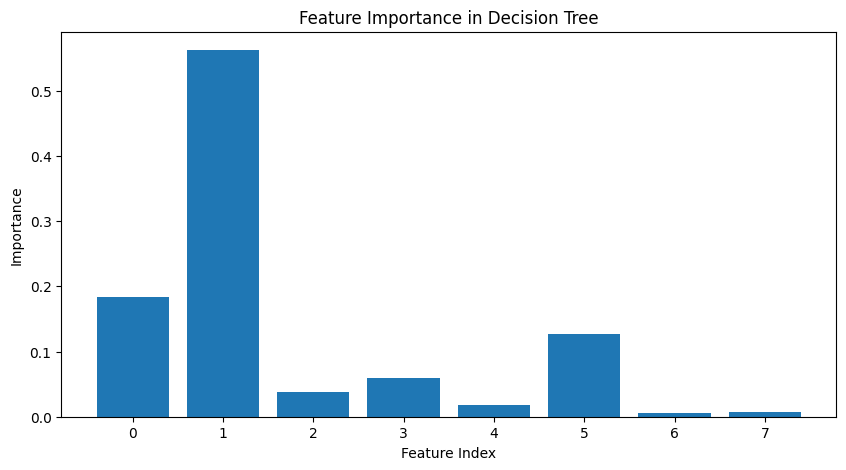

In [6]:
import matplotlib.pyplot as plt

# Get feature importance from Decision Tree
importance = tree.feature_importances_

# Plot
plt.figure(figsize=(10, 5))
plt.bar(range(len(importance)), importance)
plt.xlabel("Feature Index")
plt.ylabel("Importance")
plt.title("Feature Importance in Decision Tree")
plt.show()

# Random Forest

In [7]:
from sklearn.ensemble import RandomForestClassifier

def random_forest(data_path):
    # Load dataset
    data = np.load(data_path, allow_pickle=True)
    states, actions = zip(*data)
    states = np.array(states)
    actions = np.array(actions)

    # Split dataset
    X_train, X_test, y_train, y_test = train_test_split(
		states, actions, test_size=0.2, random_state=42
	)

    # Train Random Forest
    forest = RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42)
    forest.fit(X_train, y_train)

    # Evaluate
    y_pred = forest.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    print(f"Random Forest Accuracy for {data_path}: {accuracy * 100:.2f}%")
    joblib.dump(forest, "random_forest_model.pkl")


# Test on standardised data
random_forest("standardised_data/standardised_training_data.npy")

# Test on min-max normalised data
# random_forest("minmax_data/minmax_training_data.npy")

Random Forest Accuracy for standardised_data/standardised_training_data.npy: 89.35%
